# CSL236 — Introduction to Artificial Intelligence & Machine Learning
## Mid-Term Project: Machine Learning-Based Network Intrusion Detection System

**Team No.:** 10
**Member 1:** Cheshna Mehra | **Roll No.:** 24csu044  
**Member 2:** Faguni | **Roll No.:** 24csu290  
**Member 3:** Riya Fulambarkar| **Roll No.:** 24csu174  

### Project objective
This notebook prepares a raw network-flow dataset for machine learning and trains a simple baseline intrusion-detection model.

The workflow is deliberately organised around the evaluation rubric:

1. Understand the data
2. Handle missing values
3. Encode categorical/target values where applicable
4. Apply binning/discretisation where appropriate
5. Apply transformation and scaling
6. Investigate outliers and justify treatment
7. Apply dimensionality reduction
8. Split before fitting preprocessing, train a model, and report evaluation metrics

> **Important:** The train/test split is performed before any imputer, transformation, scaler, feature-selection or PCA fitting to avoid data leakage.

## Dataset and preprocessing philosophy

The working dataset is the network intrusion dataset already used in the supplied NIDS project notebook. The code expects the CICIDS-style CSV files to be present in:

`/content/drive/MyDrive/NIDS_Project/dataset/MachineLearningCVE`

The notebook uses class-wise sampling only to keep the project computationally manageable. Sampling is **not** a fitted preprocessing operation. All learned preprocessing parameters are calculated from the training set only.

Because this NIDS dataset contains numerical flow features and a target `Label` column, ordinary text-feature encoding is not required. The target is converted to a binary target:

- `0` = BENIGN
- `1` = ATTACK

For binning, `Flow Duration` is converted into four **ordinal** duration groups using quartile boundaries learned from the training data.

### 1. Imports and reproducibility

In [ ]:
import os
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


### 2. Connect to Google Drive and define the dataset path

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/NIDS_Project/dataset/MachineLearningCVE"

csv_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))

print("Dataset directory:", DATA_DIR)
print("Number of CSV files found:", len(csv_files))

if not csv_files:
    raise FileNotFoundError(
        "No CSV files were found. Check DATA_DIR and upload/place the dataset there."
    )

for f in csv_files:
    print("-", os.path.basename(f))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset directory: /content/drive/MyDrive/NIDS_Project/dataset/MachineLearningCVE
Number of CSV files found: 8
- Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
- Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
- Friday-WorkingHours-Morning.pcap_ISCX.csv
- Monday-WorkingHours.pcap_ISCX.csv
- Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
- Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
- Tuesday-WorkingHours.pcap_ISCX.csv
- Wednesday-workingHours.pcap_ISCX.csv


## Stage A — Understanding the data

The guideline requires the dataset shape, data types, summary statistics, missing-value count/percentage, and a separation of numerical and categorical columns.

Because the complete CICIDS-style dataset can be large, the notebook creates a **working sample** by taking at most 10,000 rows per class across all CSV files. This keeps the workflow reproducible and practical while preserving every class represented in the source files.

### 3. Inspect source files and build a class-balanced working sample

In [ ]:
MAX_SAMPLES_PER_CLASS = 10_000
CHUNK_SIZE = 100_000

class_parts = {}

for file_path in csv_files:
    print("Reading:", os.path.basename(file_path))

    for chunk in pd.read_csv(file_path, chunksize=CHUNK_SIZE, low_memory=False):
        chunk.columns = chunk.columns.str.strip()

        if "Label" not in chunk.columns:
            continue

        # Clean only the label text at this stage.
        chunk["Label"] = chunk["Label"].astype(str).str.strip()

        for label, group in chunk.groupby("Label", sort=False):
            current = sum(len(part) for part in class_parts.get(label, []))
            remaining = MAX_SAMPLES_PER_CLASS - current

            if remaining > 0:
                take = min(remaining, len(group))
                class_parts.setdefault(label, []).append(
                    group.sample(n=take, random_state=RANDOM_STATE)
                )

working_parts = []
for label, parts in class_parts.items():
    temp = pd.concat(parts, ignore_index=True)
    temp = temp.sample(frac=1, random_state=RANDOM_STATE)
    working_parts.append(temp)

raw_df = pd.concat(working_parts, ignore_index=True)
raw_df = raw_df.drop_duplicates().reset_index(drop=True)

print("\nWorking dataset shape:", raw_df.shape)
print("\nClass distribution:")
display(raw_df["Label"].value_counts())

Reading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Reading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Reading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Reading: Monday-WorkingHours.pcap_ISCX.csv
Reading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Reading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Reading: Tuesday-WorkingHours.pcap_ISCX.csv
Reading: Wednesday-workingHours.pcap_ISCX.csv

Working dataset shape: (71458, 79)

Class distribution:


,count
Label,
DDoS,10000
DoS GoldenEye,9993
BENIGN,9924
PortScan,9024
DoS Hulk,8609
FTP-Patator,5933
DoS slowloris,5385
DoS Slowhttptest,5228
SSH-Patator,3219


### 4. Shape, dtypes, summary statistics, missing values

In [ ]:
print("Shape:", raw_df.shape)

print("\nData types:")
display(raw_df.dtypes.to_frame("dtype"))

print("\nSummary statistics:")
display(raw_df.describe(include="all").T)

missing_report = pd.DataFrame({
    "Missing Count": raw_df.isna().sum(),
    "Missing Percentage": raw_df.isna().mean().mul(100)
}).sort_values("Missing Count", ascending=False)

print("\nMissing-value report:")
display(missing_report)

numeric_cols = raw_df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = raw_df.select_dtypes(exclude=np.number).columns.tolist()

# The target is categorical by nature and is not treated as a feature.
feature_categorical_cols = [c for c in categorical_cols if c != "Label"]

print("\nNumerical columns:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical feature columns:", len(feature_categorical_cols))
print(feature_categorical_cols)

print("\nJustification:")
if feature_categorical_cols:
    print("Categorical feature columns exist and will be encoded below.")
else:
    print(
        "No categorical feature columns are present. The only text column is the "
        "target Label, so feature encoding is not required. The target is mapped "
        "to a binary numerical target for classification."
    )

Shape: (71458, 79)

Data types:


,dtype
Destination Port,int64
Flow Duration,int64
Total Fwd Packets,int64
Total Backward Packets,int64
Total Length of Fwd Packets,int64
...,...
Idle Mean,float64
Idle Std,float64
Idle Max,int64
Idle Min,int64



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Destination Port,71458.0,NaN,NaN,NaN,4114.976154,12849.100886,0.0,80.0,80.0,80.0,65439.0
Flow Duration,71458.0,NaN,NaN,NaN,23199516.274035,35804739.801808,0.0,41509.0,5587919.5,18522618.25,119995180.0
Total Fwd Packets,71458.0,NaN,NaN,NaN,6.5377,51.598452,1.0,2.0,3.0,8.0,5523.0
Total Backward Packets,71458.0,NaN,NaN,NaN,6.04488,46.809541,0.0,1.0,3.0,6.0,5525.0
Total Length of Fwd Packets,71458.0,NaN,NaN,NaN,862.881035,18977.808699,0.0,2.0,55.0,369.0,2866110.0
...,...,...,...,...,...,...,...,...,...,...,...
Idle Mean,71458.0,NaN,NaN,NaN,14974154.412936,30197358.501249,0.0,0.0,0.0,10600000.0,120000000.0
Idle Std,71458.0,NaN,NaN,NaN,2082674.502317,7714968.004676,0.0,0.0,0.0,0.0,71700000.0
Idle Max,71458.0,NaN,NaN,NaN,17125563.64011,31863743.171296,0.0,0.0,0.0,10700000.0,120000000.0
Idle Min,71458.0,NaN,NaN,NaN,13410424.764169,29963619.889736,0.0,0.0,0.0,6967412.25,120000000.0



Missing-value report:


,Missing Count,Missing Percentage
Flow Bytes/s,2,0.002799
Flow Duration,0,0.000000
Destination Port,0,0.000000
Total Backward Packets,0,0.000000
Total Length of Fwd Packets,0,0.000000
...,...,...
Idle Mean,0,0.000000
Idle Std,0,0.000000
Idle Max,0,0.000000
Idle Min,0,0.000000



Numerical columns: 78
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag 

### 5. Visual exploration: class distribution and missing values

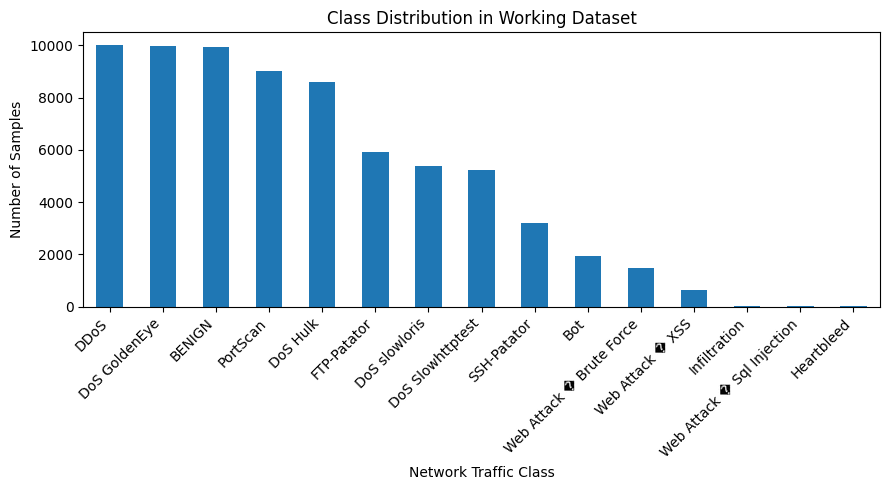

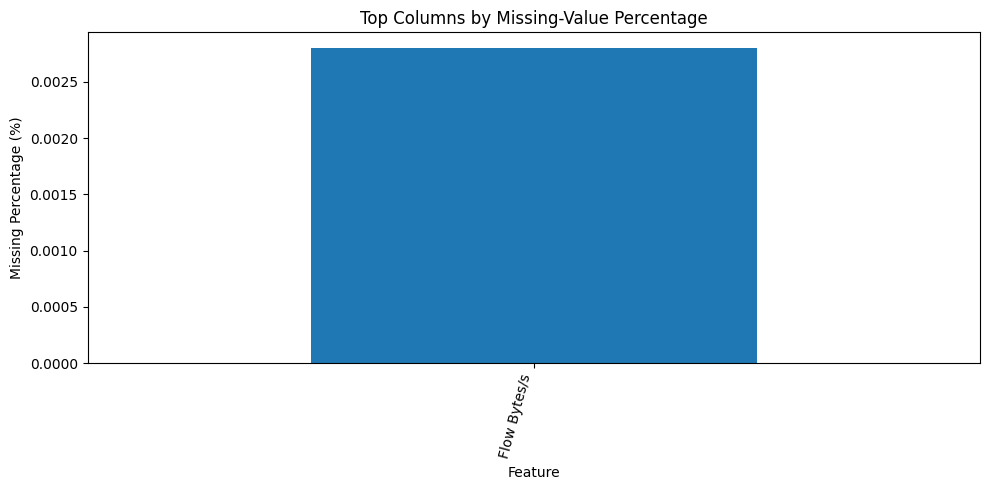

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
raw_df["Label"].value_counts().plot(kind="bar", ax=ax)
ax.set_title("Class Distribution in Working Dataset")
ax.set_xlabel("Network Traffic Class")
ax.set_ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

missing_nonzero = missing_report[missing_report["Missing Count"] > 0].head(20)

if len(missing_nonzero) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    missing_nonzero["Missing Percentage"].plot(kind="bar", ax=ax)
    ax.set_title("Top Columns by Missing-Value Percentage")
    ax.set_xlabel("Feature")
    ax.set_ylabel("Missing Percentage (%)")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values were detected in the sampled working dataset.")

## Stage B — Target preparation and train/test split

The rubric specifically warns against data leakage. Therefore:

- The target is separated first.
- The train/test split happens **before fitting** the imputer, scaler, variance filter, or PCA.
- `inf` and `-inf` values are converted to missing values separately inside each split.
- Numerical missing values are imputed using the **training-set median only**.

### Why median imputation?
Network-flow features can be skewed and can contain extreme values. Median imputation is less affected by extreme observations than mean imputation.

### 6. Prepare X and y, then split BEFORE fitting preprocessing

In [ ]:
model_df = raw_df.copy()

# Binary target: BENIGN = 0, every other class = ATTACK = 1
model_df["Binary_Label"] = (model_df["Label"].str.upper() != "BENIGN").astype(int)

X = model_df.drop(columns=["Label", "Binary_Label"])
y = model_df["Binary_Label"]

# Keep numeric predictors only; Label is the target, not a feature.
X = X.select_dtypes(include=np.number).copy()

print("Feature matrix before preprocessing:", X.shape)
print("Target distribution:")
display(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTrain shape:", X_train.shape)
print("Test shape :", X_test.shape)

Feature matrix before preprocessing: (71458, 78)
Target distribution:


,count
Binary_Label,
1,61534
0,9924



Train shape: (57166, 78)
Test shape : (14292, 78)


### 7. Handle infinite values and missing values WITHOUT leakage

In [ ]:
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

train_missing = X_train.isna().sum()
test_missing = X_test.isna().sum()

missing_train_report = pd.DataFrame({
    "Train Missing Count": train_missing,
    "Train Missing Percentage": train_missing.div(len(X_train)).mul(100),
    "Test Missing Count": test_missing,
    "Test Missing Percentage": test_missing.div(len(X_test)).mul(100)
})

print("Columns affected by missing/invalid values in training data:")
display(
    missing_train_report[missing_train_report["Train Missing Count"] > 0]
    .sort_values("Train Missing Count", ascending=False)
)

# Median is fitted on training data only.
imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("\nAfter imputation:")
print("Training missing values:", X_train_imp.isna().sum().sum())
print("Testing missing values :", X_test_imp.isna().sum().sum())

Columns affected by missing/invalid values in training data:


,Train Missing Count,Train Missing Percentage,Test Missing Count,Test Missing Percentage
Flow Bytes/s,16,0.027989,5,0.034985
Flow Packets/s,16,0.027989,5,0.034985



After imputation:
Training missing values: 0
Testing missing values : 0


### Missing-value decision

For every numerical feature with missing/invalid values, the chosen strategy is **median imputation** rather than dropping rows. Dropping rows could remove useful attack/traffic observations, while the median provides a simple robust baseline for numerical flow features.

If a column has no missing values, no imputation is applied to that column. No categorical feature imputation is needed because there are no categorical predictors in this dataset.

## Stage C — Encoding categorical data

The source dataset has a text `Label`, but this is the **target**, not an input feature.

Therefore:

- No binary/nominal feature encoding is needed for the original predictors.
- The target is converted to a binary numerical label:
  - `BENIGN → 0`
  - `all attack labels → 1`

To demonstrate appropriate encoding after binning, the derived `Flow Duration` bins are treated as an **ordinal** variable: shorter duration < longer duration. They are represented by ordered integers 0–3.

## Stage D — Binning / discretisation

`Flow Duration` is a continuous network-flow feature for which ranges can provide an interpretable view of short, medium, and long flows.

The notebook uses **equal-frequency (quartile) binning**:

- Bin 0: lowest 25%
- Bin 1: 25–50%
- Bin 2: 50–75%
- Bin 3: highest 25%

The boundaries are calculated from **training data only**. This prevents test-set information from influencing the discretisation.

### 8. Quartile binning of Flow Duration using TRAINING data only

In [ ]:
FLOW_DURATION_COL = "Flow Duration"

if FLOW_DURATION_COL not in X_train_imp.columns:
    raise KeyError(
        f"'{FLOW_DURATION_COL}' was not found. "
        "Check the exact feature name in the dataset."
    )

q1, q2, q3 = X_train_imp[FLOW_DURATION_COL].quantile([0.25, 0.50, 0.75]).tolist()

# Make boundaries strictly increasing when repeated quantiles occur.
raw_edges = [-np.inf, q1, q2, q3, np.inf]
edges = [raw_edges[0]]
for edge in raw_edges[1:]:
    if edge > edges[-1]:
        edges.append(edge)

if len(edges) < 5:
    # Fallback for a nearly constant Flow Duration column.
    edges = [-np.inf, 0, np.inf]
    bin_labels = [0, 1]
else:
    bin_labels = list(range(len(edges) - 1))

X_train_imp["Flow_Duration_Bin"] = pd.cut(
    X_train_imp[FLOW_DURATION_COL],
    bins=edges,
    labels=bin_labels,
    include_lowest=True
).astype(int)

X_test_imp["Flow_Duration_Bin"] = pd.cut(
    X_test_imp[FLOW_DURATION_COL],
    bins=edges,
    labels=bin_labels,
    include_lowest=True
).astype(int)

print("Training-derived bin boundaries:")
print(edges)

print("\nTraining bin counts:")
display(X_train_imp["Flow_Duration_Bin"].value_counts().sort_index())

print("\nTest bin counts:")
display(X_test_imp["Flow_Duration_Bin"].value_counts().sort_index())

Training-derived bin boundaries:
[-inf, 42134.5, 5591421.0, 18539000.5, inf]

Training bin counts:


,count
Flow_Duration_Bin,
0,14292
1,14291
2,14291
3,14292



Test bin counts:


,count
Flow_Duration_Bin,
0,3606
1,3546
2,3605
3,3535


### 9. Visualise the binned feature

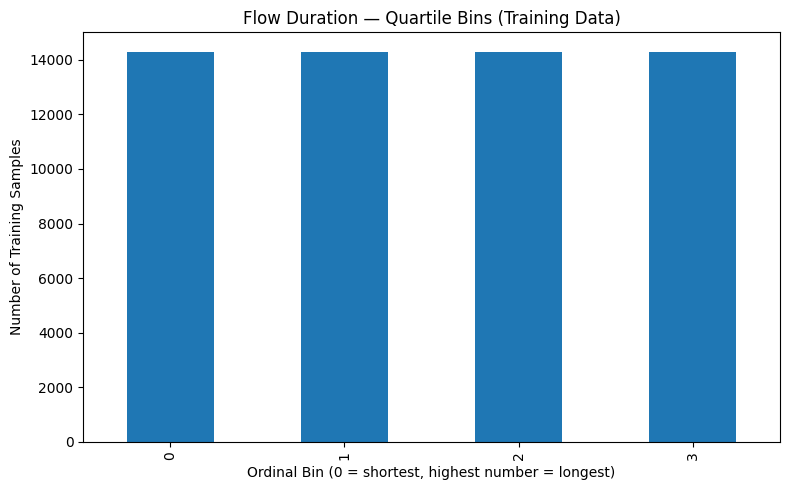

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
X_train_imp["Flow_Duration_Bin"].value_counts().sort_index().plot(
    kind="bar", ax=ax
)
ax.set_title("Flow Duration — Quartile Bins (Training Data)")
ax.set_xlabel("Ordinal Bin (0 = shortest, highest number = longest)")
ax.set_ylabel("Number of Training Samples")
plt.tight_layout()
plt.show()

## Stage E — Scaling / transformation

Network-flow variables such as durations, packet counts, byte counts, and rates can be highly skewed.

The transformation below:

1. Finds non-negative training features with strong right skew (`skewness > 2`).
2. Applies `log1p(x)` to those features.
3. Fits `StandardScaler` on the transformed training data only.
4. Applies the same transformation/scaling to the test data.

The set of transformed columns is selected from the training set only.

### 10. Identify strongly skewed non-negative features from TRAINING data only

In [ ]:
candidate_features = [
    c for c in X_train_imp.columns
    if c != "Flow_Duration_Bin"
]

skewed_cols = []

for col in candidate_features:
    series = X_train_imp[col]
    if (series >= 0).all() and series.nunique() > 2:
        if abs(series.skew()) > 2:
            skewed_cols.append(col)

print("Number of strongly skewed non-negative features:", len(skewed_cols))
print(skewed_cols[:30], "..." if len(skewed_cols) > 30 else "")

Number of strongly skewed non-negative features: 42
['Destination Port', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Min', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Fwd IAT Mean', 'Fwd IAT Std', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Packet Length Variance', 'Down/Up Ratio', 'Avg Fwd Segment Size', 'Fwd Header Length.1'] ...


### 11. Apply log transformation and standardisation

In [ ]:
X_train_trans = X_train_imp.copy()
X_test_trans = X_test_imp.copy()

for col in skewed_cols:
    X_train_trans[col] = np.log1p(X_train_trans[col])
    X_test_trans[col] = np.log1p(X_test_trans[col])

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_trans),
    columns=X_train_trans.columns,
    index=X_train_trans.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_trans),
    columns=X_test_trans.columns,
    index=X_test_trans.index
)

print("Features before scaling:", X_train_trans.shape[1])
print("Scaled training shape :", X_train_scaled.shape)
print("Scaled testing shape  :", X_test_scaled.shape)

Features before scaling: 79
Scaled training shape : (57166, 79)
Scaled testing shape  : (14292, 79)


## Stage F — Outlier treatment

Outliers are investigated using the **IQR rule** on the training data.

For this NIDS problem, extreme flow values are not automatically deleted. Very large packet/byte counts or flow durations can represent genuine network behaviour rather than data-entry errors. Therefore, the baseline treatment is:

- detect and report IQR outliers;
- retain them;
- use log transformation for strongly right-skewed non-negative variables;
- use standardisation for the model.

This is preferable to deleting unusual observations without evidence that they are erroneous.

### 12. IQR-based outlier investigation on training data

In [ ]:
outlier_rows = []

for col in X_train_imp.columns:
    q1_col = X_train_imp[col].quantile(0.25)
    q3_col = X_train_imp[col].quantile(0.75)
    iqr = q3_col - q1_col

    if iqr == 0:
        count = 0
    else:
        lower = q1_col - 1.5 * iqr
        upper = q3_col + 1.5 * iqr
        count = ((X_train_imp[col] < lower) | (X_train_imp[col] > upper)).sum()

    outlier_rows.append({
        "Feature": col,
        "IQR Outlier Count": int(count),
        "Outlier Percentage": round(100 * count / len(X_train_imp), 3)
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values(
    "IQR Outlier Count", ascending=False
)

display(outlier_report.head(20))

print(
    "\nTreatment decision: IQR outliers are retained because extreme network-flow "
    "values may be genuine traffic characteristics. Skewed non-negative features "
    "are log-transformed instead of deleting observations."
)

,Feature,IQR Outlier Count,Outlier Percentage
37,Bwd Packets/s,12997,22.736
15,Flow Packets/s,12989,22.722
36,Fwd Packets/s,12956,22.664
20,Fwd IAT Total,12872,22.517
23,Fwd IAT Max,12794,22.380
1,Flow Duration,12749,22.302
18,Flow IAT Max,12737,22.281
76,Idle Max,12727,22.263
17,Flow IAT Std,11825,20.685
26,Bwd IAT Mean,11626,20.337



Treatment decision: IQR outliers are retained because extreme network-flow values may be genuine traffic characteristics. Skewed non-negative features are log-transformed instead of deleting observations.


### 13. Example boxplot before transformation for a high-outlier feature

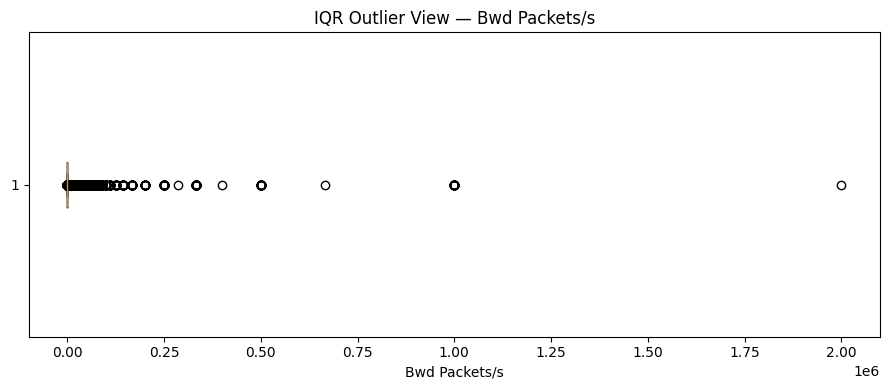

In [ ]:
plot_col = outlier_report.iloc[0]["Feature"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot(X_train_imp[plot_col].dropna(), vert=False)
ax.set_title(f"IQR Outlier View — {plot_col}")
ax.set_xlabel(plot_col)
plt.tight_layout()
plt.show()

## Stage G — Dimensionality reduction

A **two-step dimensionality reduction** approach is used:

1. `VarianceThreshold` removes features with zero variance.
2. PCA is then fitted to the remaining scaled training features and retains **95% cumulative explained variance**.

PCA is appropriate here because the NIDS dataset contains many correlated numerical flow measurements. PCA creates a smaller set of components while retaining most of the variance.

The number of features before and after reduction is explicitly reported.

### 14. Variance threshold followed by PCA

In [ ]:
before_reduction = X_train_scaled.shape[1]

variance_selector = VarianceThreshold(threshold=0.0)

X_train_var = variance_selector.fit_transform(X_train_scaled)
X_test_var = variance_selector.transform(X_test_scaled)

after_variance = X_train_var.shape[1]

pca = PCA(n_components=0.95, random_state=RANDOM_STATE)

X_train_pca = pca.fit_transform(X_train_var)
X_test_pca = pca.transform(X_test_var)

after_pca = X_train_pca.shape[1]

print("Feature count before reduction :", before_reduction)
print("After variance threshold       :", after_variance)
print("After PCA (95% variance)       :", after_pca)
print("Variance retained              :", round(pca.explained_variance_ratio_.sum(), 4))

Feature count before reduction : 79
After variance threshold       : 69
After PCA (95% variance)       : 17
Variance retained              : 0.9582


### 15. PCA explained variance visualisation

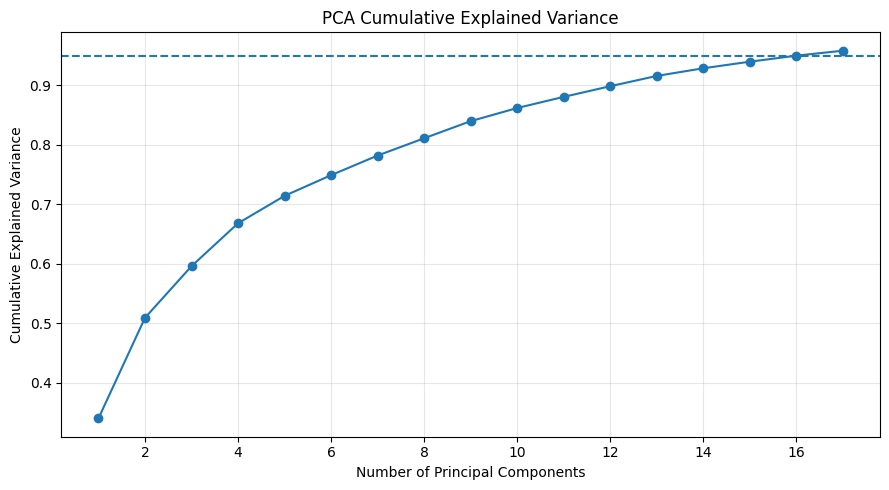

In [ ]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
ax.axhline(0.95, linestyle="--")
ax.set_title("PCA Cumulative Explained Variance")
ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Stage H — Model training

A simple **Logistic Regression** classifier is used as the baseline model.

This is intentionally a baseline rather than an accuracy-optimised model because the course guideline states that the evaluation focuses primarily on the **quality and justification of preprocessing**, not on achieving the highest accuracy.

The model is trained only on the PCA-transformed training set and evaluated on the untouched test set.

### 16. Train baseline model

In [ ]:
baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

start_time = time.time()

baseline_model.fit(X_train_pca, y_train)

training_time = time.time() - start_time

y_pred = baseline_model.predict(X_test_pca)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0)
}

print("Training time:", round(training_time, 2), "seconds")
for name, value in metrics.items():
    print(f"{name}: {value:.4f}")

Training time: 0.23 seconds
Accuracy: 0.9253
Precision: 0.9800
Recall: 0.9322
F1 Score: 0.9555


### 17. Classification report and confusion matrix

===== BASELINE LOGISTIC REGRESSION =====
              precision    recall  f1-score   support

      BENIGN       0.68      0.88      0.77      1985
      ATTACK       0.98      0.93      0.96     12307

    accuracy                           0.93     14292
   macro avg       0.83      0.91      0.86     14292
weighted avg       0.94      0.93      0.93     14292



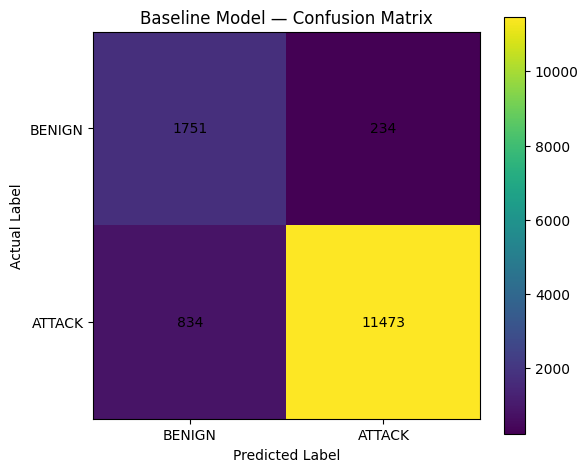

In [ ]:
print("===== BASELINE LOGISTIC REGRESSION =====")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        zero_division=0
    )
)

cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)

ax.set_title("Baseline Model — Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_xticks([0, 1], ["BENIGN", "ATTACK"])
ax.set_yticks([0, 1], ["BENIGN", "ATTACK"])

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center")

fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Preprocessing summary

| Stage | Technique | Application / Decision |
|---|---|---|
| Missing values | Median imputation | Numerical features with missing/invalid values; median fitted on training data |
| Categorical encoding | Not required for original predictors | No categorical input features; `Label` is the target |
| Target encoding | Binary mapping | `BENIGN = 0`, all attacks = `1` |
| Binning | Equal-frequency quartile bins | `Flow Duration`, boundaries learned from training data |
| Transformation | `log1p` | Strongly right-skewed, non-negative training features |
| Scaling | StandardScaler | All transformed numerical predictors; fitted on training data |
| Outliers | IQR detection, retain | Extreme network values may be genuine; no reflex deletion |
| Dimensionality reduction | VarianceThreshold + PCA | Remove zero-variance features, then retain 95% variance |
| Model | Logistic Regression | Simple baseline on the fully preprocessed data |

### Leakage check
The split was performed before fitting the imputer, scaler, variance selector, or PCA. Binning boundaries and skewed-feature selection were also derived from training data only.

### 18. Final project summary

In [ ]:
summary = pd.DataFrame({
    "Item": [
        "Working dataset rows",
        "Original feature count",
        "Features after variance threshold",
        "PCA components retained",
        "Train rows",
        "Test rows",
        "Training time (sec)",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Value": [
        len(raw_df),
        before_reduction,
        after_variance,
        after_pca,
        len(X_train),
        len(X_test),
        round(training_time, 2),
        round(metrics["Accuracy"], 4),
        round(metrics["Precision"], 4),
        round(metrics["Recall"], 4),
        round(metrics["F1 Score"], 4)
    ]
})

display(summary)

,Item,Value
0,Working dataset rows,71458.0000
1,Original feature count,79.0000
2,Features after variance threshold,69.0000
3,PCA components retained,17.0000
4,Train rows,57166.0000
5,Test rows,14292.0000
6,Training time (sec),0.2300
7,Accuracy,0.9253
8,Precision,0.9800
9,Recall,0.9322


## Conclusion and observations

- The raw NIDS data was inspected for shape, data types, class distribution, missing values, and numerical/categorical columns.
- Missing numerical values were handled with **training-set median imputation**.
- The target was converted into a binary classification problem.
- `Flow Duration` was discretised using **training-derived quartile boundaries**.
- Strongly skewed non-negative features were transformed using `log1p`, followed by standardisation.
- Outliers were investigated with the IQR rule and retained because extreme network-flow values can be legitimate.
- Dimensionality was reduced using a zero-variance filter followed by PCA retaining 95% explained variance.
- A Logistic Regression baseline was trained and evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

### What could be done next
A future version could compare additional classifiers such as Random Forest or Extra Trees, tune hyperparameters, and investigate multiclass attack-type prediction. Such extensions are optional and should not replace the required preprocessing justification.

## External sources / references

Manocchio, L. D., Layeghy, S., Gallagher, M., & Portmann, M. (2025). An empirical evaluation of preprocessing methods for machine learning based network intrusion detection systems. Engineering Applications of Artificial Intelligence, 158, 111289. https://doi.org/10.1016/j.engappai.2025.111289

**Software used:** Python, pandas, NumPy, Matplotlib, and scikit-learn.

If any external dataset documentation, tutorial, code, or article is added later, cite it here and state exactly what was used.